# Bayesian search: two Optuna runs

In [1]:
!pip install plotly kaleido==0.2.1

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy.interpolate import PchipInterpolator
import plotly.graph_objects as go, plotly.io as pio
pio.kaleido.scope.mathjax = None
pio.renderers.default = "png"

import os; FIGDIR = "figures"; os.makedirs(FIGDIR, exist_ok=True)
INK, BLUE, ORANGE = "#52514e", "#2a78d6", "#eb6834"
FACTORS = ["feature_source", "mode", "max_crops", "roi_size", "pool_ks", "thresh"]
METRIC, COUNT = "f1_center", "mae"

In [3]:
r1 = pd.read_csv("optuna1_results.csv").rename(columns={METRIC: "F1", COUNT: "MAE"})
r2 = pd.read_csv("optuna2_results.csv").rename(columns={METRIC: "F1", COUNT: "MAE"})
runs = {"run1": r1, "run2": r2}
pd.DataFrame({k: {"trials": len(v), "F1_max": v.F1.max(), "MAE_min": v.MAE.min(),
                  "above_0.3": int((v.F1 >= .3).sum())} for k, v in runs.items()}).T

,trials,F1_max,MAE_min,above_0.3
run1,1000.0,0.4773,3.82,888.0
run2,400.0,0.4761,3.69,397.0


## Median behaviour of every level

In [4]:
levels = []
for name, d in runs.items():
    for f in FACTORS:
        if d[f].nunique() > 8: continue
        g = d.groupby(f).agg(n=("F1", "size"), F1_median=("F1", "median"),
                             MAE_median=("MAE", "median"))
        levels.append(g.reset_index().rename(columns={f: "level"}).assign(run=name, factor=f))
levels = pd.concat(levels)[["run", "factor", "level", "n", "F1_median", "MAE_median"]]
levels

,run,factor,level,n,F1_median,MAE_median
0,run1,feature_source,feats,802,0.42515,4.700
1,run1,feature_source,mu,129,0.37390,7.820
2,run1,feature_source,z,69,0.33730,12.590
0,run1,mode,average,815,0.42420,4.750
1,run1,mode,majority_voting,185,0.29080,8.840
0,run1,max_crops,5,68,0.33795,6.880
1,run1,max_crops,30,114,0.38470,6.780
2,run1,max_crops,60,138,0.40995,5.850
3,run1,max_crops,90,680,0.42470,4.950
0,run1,roi_size,7,139,0.43420,7.980


## Threshold has no trend above the retained range

In [5]:
pooled = pd.concat([r1.assign(run="run1"), r2.assign(run="run2")], ignore_index=True)

hi = pooled[pooled.thresh > 0.58]
sub = hi[(hi.feature_source == "feats") & (hi["mode"] == "average")]
rows = []
for name, d in [("pooled, thresh>0.58", hi), ("feats+average, thresh>0.58", sub)]:
    sf, sm = spearmanr(d.thresh, d.F1), spearmanr(d.thresh, d.MAE)
    rows.append(dict(subset=name, n=len(d), rho_F1=sf.statistic, p_F1=sf.pvalue,
                     rho_MAE=sm.statistic, p_MAE=sm.pvalue))
pd.DataFrame(rows)

,subset,n,rho_F1,p_F1,rho_MAE,p_MAE
0,"pooled, thresh>0.58",786,-0.012265,0.731351,0.022072,0.536639
1,"feats+average, thresh>0.58",614,-0.050042,0.215624,0.097857,0.015280


In [6]:
low = pooled[pooled.thresh < 0.30]
pd.Series({"n below 0.30": len(low), "MAE median below": low.MAE.median(),
           "MAE median rest": pooled[pooled.thresh >= 0.30].MAE.median()})

n below 0.30        128.00
MAE median below      5.69
MAE median rest       4.62
dtype: float64

## Pareto fronts

In [7]:
def front(d):
    f, m = d.F1.values, d.MAE.values
    nd = [not np.any((f >= f[i]) & (m <= m[i]) & ((f > f[i]) | (m < m[i]))) for i in range(len(d))]
    return d[np.array(nd)]

for name, d in runs.items():
    nd = front(d)
    keys = [c for c in FACTORS if c in nd.columns]
    pts = nd.groupby(keys + ["F1", "MAE"], as_index=False).size().sort_values("F1", ascending=False)
    print(name, "| non-dominated trials:", len(nd), "| distinct points:", len(pts))
    display(pts)

run1 | non-dominated trials: 72 | distinct points: 11


,feature_source,mode,max_crops,roi_size,pool_ks,thresh,F1,MAE,size
2,feats,average,90,9,7,0.6732,0.4773,4.87,1
4,feats,average,90,9,7,0.6872,0.4755,4.75,6
0,feats,average,90,9,7,0.6435,0.4728,4.68,1
1,feats,average,90,9,7,0.6541,0.4724,4.63,18
3,feats,average,90,9,7,0.6872,0.4691,4.45,8
8,feats,average,90,11,7,0.6541,0.4603,4.35,16
5,feats,average,90,11,7,0.6000,0.4587,4.15,3
6,feats,average,90,11,7,0.6435,0.4544,4.05,1
7,feats,average,90,11,7,0.6541,0.4529,4.00,16
9,feats,majority_voting,90,9,7,0.6039,0.3758,3.89,1


run2 | non-dominated trials: 8 | distinct points: 8


,feature_source,mode,max_crops,roi_size,pool_ks,thresh,F1,MAE,size
1,feats,average,90,9,9,0.5997,0.4761,4.55,1
2,feats,average,90,9,9,0.6277,0.4758,4.44,1
3,feats,average,90,9,11,0.5954,0.4649,3.92,1
7,feats,average,90,11,11,0.5161,0.4505,3.87,1
4,feats,average,90,11,9,0.6277,0.4475,3.85,1
5,feats,average,90,11,11,0.3780,0.4354,3.80,1
0,feats,average,60,9,11,0.5878,0.4335,3.71,1
6,feats,average,90,11,11,0.4835,0.4026,3.69,1


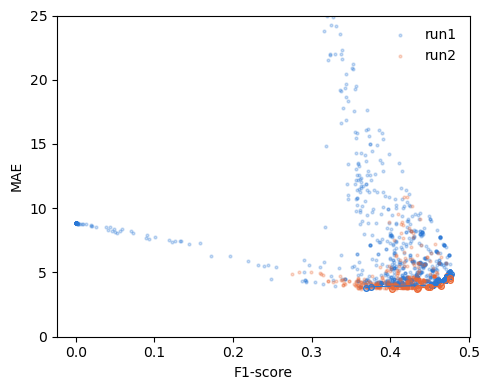

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
for name, d, c in [("run1", r1, BLUE), ("run2", r2, ORANGE)]:
    ax.scatter(d.F1, d.MAE, s=4, alpha=.25, color=c, label=name)
    nd = front(d).sort_values("F1")
    ax.plot(nd.F1, nd.MAE, "o-", ms=4, lw=.8, color=c, mfc="none")
ax.set_xlabel("F1-score"); ax.set_ylabel("MAE"); ax.set_ylim(0, 25); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(f"{FIGDIR}/optuna_scatter_pareto.pdf"); plt.show()

## Parallel coordinates

In [9]:
def parallel(df, dims, metric, out, size=(1000, 420), fonts=(11, 9, 9)):
    df = df.reset_index(drop=True); cols = dims + [metric]; n = len(cols)
    rng = np.random.default_rng(42); norm, ticks = {}, {}
    for c in dims:
        if df[c].dtype == object:
            cat = pd.Categorical(df[c]); k = len(cat.categories)
            base = cat.codes / max(k - 1, 1) * .9 + .05
            norm[c] = np.clip(base + rng.uniform(-.04, .04, len(df)), 0, 1)
            ticks[c] = (np.linspace(.05, .95, k), list(cat.categories))
        else:
            lo, hi = df[c].min(), df[c].max(); d = (hi - lo) or 1
            norm[c] = np.clip((df[c] - lo) / d + rng.uniform(-.02, .02, len(df)), 0, 1)
            ticks[c] = None
    lo, hi = df[metric].min(), df[metric].max(); d = (hi - lo) or 1
    q = ((df[metric] - lo) / d).values
    norm[metric] = np.clip(q + rng.uniform(-.02, .02, len(df)), 0, 1); ticks[metric] = None
    xa = np.arange(n, dtype=float); xs = np.linspace(0, n - 1, 80)
    cmap = plt.cm.turbo; fig = go.Figure(); order = np.argsort(q)
    edges = np.linspace(0, 1, 71)
    for b in range(70):
        sel = order[(q[order] >= edges[b]) & (q[order] < edges[b + 1] + (1e-9 if b == 69 else 0))]
        if not len(sel): continue
        X, Y = [], []
        for i in sel:
            y = np.array([norm[c][i] for c in cols])
            X += list(xs) + [None]; Y += list(np.clip(PchipInterpolator(xa, y)(xs), 0, 1)) + [None]
        mid = (edges[b] + edges[b + 1]) / 2; r = cmap(mid)
        fig.add_trace(go.Scatter(x=X, y=Y, mode="lines", showlegend=False, hoverinfo="skip",
            line=dict(width=1.2, color=f"rgba({r[0]*255:.0f},{r[1]*255:.0f},{r[2]*255:.0f},{.2+mid*.3:.2f})")))
    for i, c in enumerate(cols):
        fig.add_shape(type="line", x0=i, x1=i, y0=-.02, y1=1.02, line=dict(color="black", width=1.4))
        fig.add_annotation(x=i, y=1.10, text=f"<b>{c}</b>", showarrow=False, font=dict(size=fonts[0]))
        if ticks[c]:
            for v, t in zip(*ticks[c]):
                fig.add_annotation(x=i, y=v, text=f"  <b>{t}</b>", showarrow=False,
                                   xanchor="left", xshift=6, font=dict(size=fonts[1]))
        elif c != metric:
            for yv, tv in [(0, df[c].min()), (1, df[c].max())]:
                fig.add_annotation(x=i, y=yv, text=f"  {tv:.3g}", showarrow=False,
                                   xanchor="left", xshift=6, font=dict(size=fonts[1]))
    fig.update_layout(xaxis=dict(visible=False, range=[-.35, n - 1 + .65]),
                      yaxis=dict(visible=False, range=[-.04, 1.14]),
                      plot_bgcolor="white", paper_bgcolor="white",
                      width=size[0], height=size[1], margin=dict(l=10, r=10, t=30, b=10))
    open(out, "wb").write(fig.to_image(format="pdf"))
    return fig

run1 | drawn: 888 of 1000


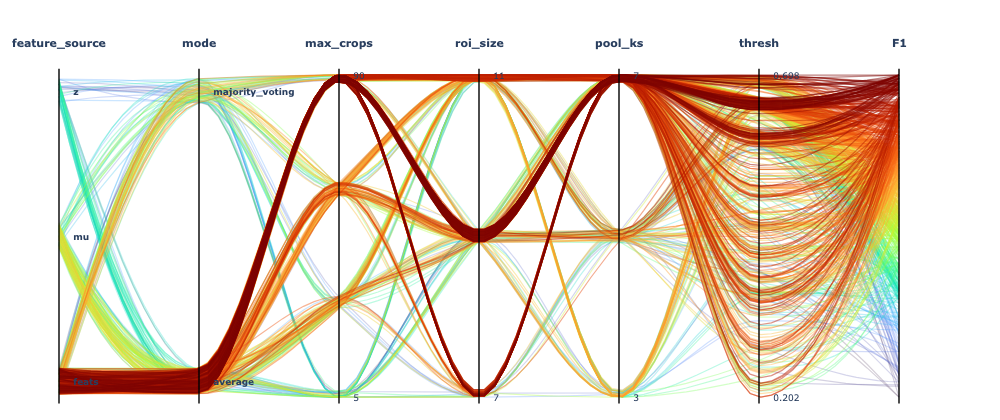

run2 | drawn: 397 of 400


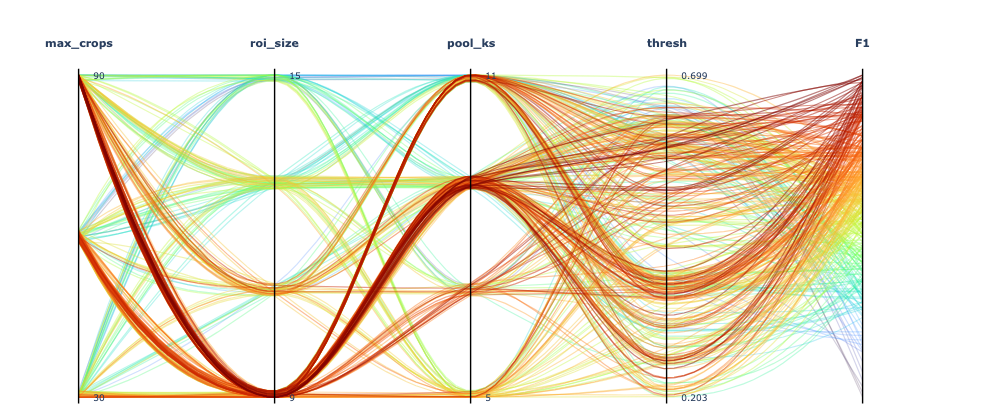

In [10]:
for name, d in runs.items():
    sel = d[d.F1 >= .3]
    dims = [c for c in FACTORS if c in sel.columns and sel[c].nunique() > 1]
    print(name, "| drawn:", len(sel), "of", len(d))
    parallel(sel[dims + ["F1"]].copy(), dims, "F1",
             f"{FIGDIR}/optuna_parallel_{name}.pdf").show()